# Runtime curve walkthrough: convective wind × real estate

Reads the proposed artifact and calls the curves through the cell's reference evaluator, the way a Hazard M3
consumer would. Damage only: no frequency, no yearly loss. See
[`00_curve_curation_walkthrough.ipynb`](00_curve_curation_walkthrough.ipynb) for how the curves are built.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "convective_wind_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "convective_wind_real_estate__model_v0_1__docs_r1__curve_artifact.json"
REG = "convective_wind_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/convective_wind/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))
import convective_wind_real_estate_curve_eval as ev  # the cell's reference evaluator

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])


def call(request: dict) -> dict:
    """Send one request through the cell's reference evaluator; return a flat row."""
    try:
        out = ev.evaluate_damage_call(ART, request)
    except ev.DamageCallError as err:
        return {"status": "error", "curve_id": None, "damage_ratio": None, "reason": err.code}
    r = out["failure_unit_results"][0]
    return {"status": r["status"], "curve_id": r["curve_id"], "damage_ratio": r["scalar_central_dr"],
            "reason": "; ".join(r["withheld_reason_codes"]) or None}

artifact: docs/cells/convective_wind_real_estate/proposed/convective_wind_real_estate__model_v0_1__docs_r1__curve_artifact.json
convective_wind_real_estate | model v0.1 | CONVECTIVE_WIND_REAL_ESTATE_EF_SCREENING_V0_1 | promotion: proposed | canonical: False


## 1. What the artifact contains

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)

,field,value
0,cell,convective_wind_real_estate
1,damage code,CONVECTIVE_WIND_REAL_ESTATE_EF_SCREENING_V0_1
2,model / docs,model v0.1 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_expert_elicited_damage_degrees_priced_by_damage_state


,id,treatment,denominator
0,CWRE_BUILDING_STRUCTURE,primary_nonzero,"structure replacement cost new of the same reference building (no land, contents, site works or depreciation)"
1,CWRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,straight_line_convective,convective_gust_3s_10m_mph,mph,"[0.0, 255.0]",reference_building_id,-,3
1,tornado_direct_hit,tornado_gust_3s_10m_mph,mph,"[0.0, 255.0]",reference_building_id,-,3


## 2. Request contract

Each pathway reads only its own gust field. An EF rating is never a speed.

In [3]:
display(pd.DataFrame(ART["evaluation_contract"]["accepted_axis_payloads"]))
display(pd.DataFrame(ART["pathways"][0]["selector_logic"])[["field", "required", "allowed", "effect"]])
for p in ART["pathways"]:
    ax = p["hazard_axis"]
    print(p["pathway_id"], "->", ax["preferred_input_field"], ax["valid_range"], "|", ax["bridge"])

,pathway_id,mode,required_fields
0,straight_line_convective,gust_mph,[convective_gust_3s_10m_mph]
1,tornado_direct_hit,gust_mph,[tornado_gust_3s_10m_mph]


,field,required,allowed,effect
0,reference_building_id,True,"[RE_RES_SFD_1S_SLAB, RE_IND_WAREHOUSE, RE_COM_OFFICE_3S_SLAB]",Fixed identity of the reference building; picks the EF damage indicator.


straight_line_convective -> convective_gust_3s_10m_mph [0.0, 255.0] | none in Damage; Hazard delivers the ASCE 7-22 3-s gust at 10 m, Exposure C
tornado_direct_hit -> tornado_gust_3s_10m_mph [0.0, 255.0] | none in Damage; Hazard's EF band midpoint gust is accepted as a damage-inferred T4 bridge


## 3. All records, straight from the artifact

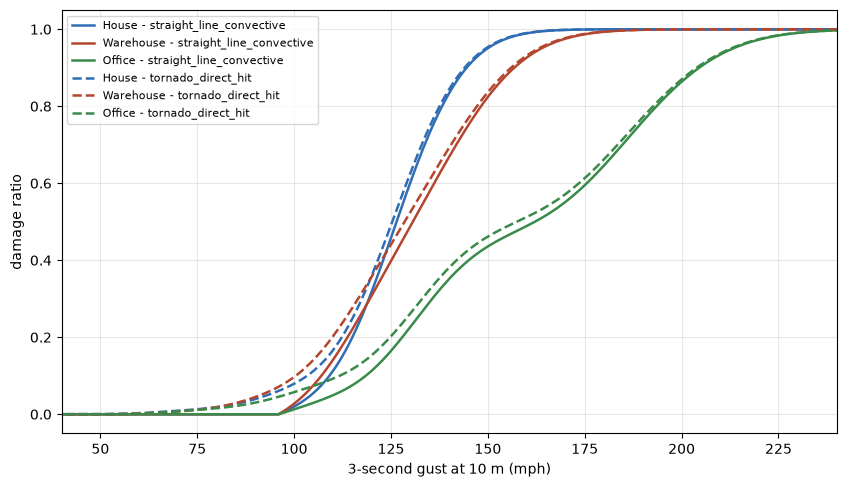

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
style = {"straight_line_convective": "-", "tornado_direct_hit": "--"}
colors = {"RE_RES_SFD_1S_SLAB": "#2f6db4", "RE_IND_WAREHOUSE": "#b4462f", "RE_COM_OFFICE_3S_SLAB": "#3a8a4a"}
for p in ART["pathways"]:
    for r in p["curve_records"]:
        b = r["selector_match"]["reference_building_id"]
        x, y = zip(*r["parameters"]["points"])
        ax.plot(x, y, style[p["pathway_id"]], color=colors[b], lw=1.8, label=f'{NAMES[b]} - {p["pathway_id"]}')
ax.set_xlim(40, 240)
ax.set_xlabel("3-second gust at 10 m (mph)")
ax.set_ylabel("damage ratio")
ax.legend(fontsize=8)
save(fig, "01_artifact_records.png")
plt.show()

## 4. Calling the curves

A grid of gusts for each building and pathway, every value from the evaluator.

In [5]:
rows = []
for p in ("straight_line_convective", "tornado_direct_hit"):
    field = next(x for x in ART["pathways"] if x["pathway_id"] == p)["hazard_axis"]["preferred_input_field"]
    for b in ("RE_RES_SFD_1S_SLAB", "RE_IND_WAREHOUSE", "RE_COM_OFFICE_3S_SLAB"):
        for g in (80, 96, 100, 110, 120, 130, 140, 160):
            res = call({"pathway_id": p, "failure_unit_id": "CWRE_BUILDING_STRUCTURE", "reference_building_id": b, field: g})
            rows.append({"pathway": p, "building": NAMES[b], "gust_mph": g, "damage_ratio": res["damage_ratio"]})
grid = pd.DataFrame(rows).pivot_table(index=["pathway", "building"], columns="gust_mph", values="damage_ratio")
display(grid.style.format("{:.1%}"))

Hazard sends a tornado as the midpoint gust of its EF band. The damage for a direct hit at each band:

In [6]:
ef_mid = {"EF0": 75.0, "EF1": 98.0, "EF2": 123.0, "EF3": 150.5, "EF4": 183.0, "EF5": 227.0}
rows = []
for b in ("RE_RES_SFD_1S_SLAB", "RE_IND_WAREHOUSE", "RE_COM_OFFICE_3S_SLAB"):
    for ef_label, g in ef_mid.items():
        res = call({"pathway_id": "tornado_direct_hit", "failure_unit_id": "CWRE_BUILDING_STRUCTURE",
                    "reference_building_id": b, "tornado_gust_3s_10m_mph": g})
        rows.append({"building": NAMES[b], "EF band": f"{ef_label} ({g:g} mph)", "damage_ratio": res["damage_ratio"]})
display(pd.DataFrame(rows).pivot(index="building", columns="EF band", values="damage_ratio").style.format("{:.1%}"))

EF band,EF0 (75 mph),EF1 (98 mph),EF2 (123 mph),EF3 (150.5 mph),EF4 (183 mph),EF5 (227 mph)
building,,,,,,
House,1.3%,6.9%,43.7%,95.7%,100.0%,100.0%
Office,1.1%,5.1%,18.1%,46.4%,69.5%,98.7%
Warehouse,1.2%,8.3%,40.7%,84.3%,99.6%,100.0%


## 5. Fail-closed behaviour

Out-of-contract requests are withheld or rejected; nothing is silently priced.

In [7]:
base = {"pathway_id": "straight_line_convective", "failure_unit_id": "CWRE_BUILDING_STRUCTURE",
        "reference_building_id": "RE_RES_SFD_1S_SLAB", "convective_gust_3s_10m_mph": 130.0}
cases = {
    "valid request": base,
    "gust above 255 mph": {**base, "convective_gust_3s_10m_mph": 260.0},
    "contents unit": {**base, "failure_unit_id": "CWRE_BUILDING_CONTENTS"},
    "negative gust": {**base, "convective_gust_3s_10m_mph": -5.0},
    "tornado field on the straight-line pathway": {k: v for k, v in base.items() if k != "convective_gust_3s_10m_mph"} | {"tornado_gust_3s_10m_mph": 130.0},
    "EF rating instead of a gust": {"pathway_id": "tornado_direct_hit", "failure_unit_id": "CWRE_BUILDING_STRUCTURE",
                                    "reference_building_id": "RE_RES_SFD_1S_SLAB", "ef_rating": "EF2"},
    "profile ID instead of the selector": {**base, "reference_building_id": "re_house_1s_wood_slab"},
    "hurricane pathway": {**base, "pathway_id": "tropical_cyclone_wind"},
}
display(pd.DataFrame([{"case": k, **call(v)} for k, v in cases.items()]))

,case,status,curve_id,damage_ratio,reason
0,valid request,conditional,CWRE_RES_EF_FR12_STRAIGHT_LINE_ONSET96,0.602244,NaN
1,gust above 255 mph,withheld,CWRE_RES_EF_FR12_STRAIGHT_LINE_ONSET96,NaN,ABOVE_SOURCE_VALID_RANGE
2,contents unit,withheld,NaN,NaN,NO_RUNTIME_CURVE_FOR_PATHWAY_UNIT; CONTENTS_DEFERRED_SEPARATE_FAILURE_UNIT
3,negative gust,error,NaN,NaN,AXIS_OUTSIDE_VALID_RANGE
4,tornado field on the straight-line pathway,error,NaN,NaN,AXIS_PAYLOAD_REQUIRED
5,EF rating instead of a gust,error,NaN,NaN,AXIS_PAYLOAD_REQUIRED
6,profile ID instead of the selector,error,NaN,NaN,REFERENCE_BUILDING_ID_UNKNOWN
7,hurricane pathway,error,NaN,NaN,PATHWAY_ID_UNKNOWN


## 6. From damage ratio to dollars (illustration)

The artifact withholds dollars until Hazard qualifies each building value; here the Hazard profile budgets are used only to show the arithmetic `loss = DR × replacement cost new`.

In [8]:
rows = []
for b, budget in BUDGETS_USD.items():
    res = call({"pathway_id": "straight_line_convective", "failure_unit_id": "CWRE_BUILDING_STRUCTURE",
                "reference_building_id": b, "convective_gust_3s_10m_mph": 120.0})
    rows.append({"building": NAMES[b], "replacement cost new": budget, "DR at 120 mph straight-line": res["damage_ratio"],
                 "loss (illustration)": res["damage_ratio"] * budget})
display(pd.DataFrame(rows).style.format({"replacement cost new": "${:,.0f}", "DR at 120 mph straight-line": "{:.1%}",
                                         "loss (illustration)": "${:,.0f}"}))

,building,replacement cost new,DR at 120 mph straight-line,loss (illustration)
0,House,"$405,000",31.8%,"$128,806"
1,Warehouse,"$11,000,000",30.8%,"$3,386,130"
2,Office,"$10,800,000",11.3%,"$1,219,169"


## 7. Capability: what the artifact may and may not be used for

In [9]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,straight_line_convective,conditional,withheld,not_carried,CWRE_BUILDING_CONTENTS
1,tornado_direct_hit,conditional,withheld,not_carried,CWRE_BUILDING_CONTENTS


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts D-CWRE-01 to D-CWRE-16
  - consumer value qualification of each reference budget (shared with flood_real_estate)
  - reviewer accepts the T4 straight-line transfer and the cost assignment
  - independent review of the package


## 8. Not in this notebook

- Frequency and yearly loss belong to Hazard; the order-of-magnitude comparison with FEMA's National Risk Index is
  `scripts/reference_helpers/convective_wind_real_estate_nri_check.py` (results in the cell's `NRI_CHECK` table).
- The Hazard loader probe is `check_convective_wind_real_estate_hazard_loader.py`.